# 05 · Acuerdo entre los evaluadores de las encuestas originales

Las etiquetas de las 2.000 imágenes publicitarias (`etiquetas_originales.csv`) provienen de **20 encuestas de 100 imágenes** (carpeta `images_or/encuestas/Test_ecuestados/Tests`). Cada encuesta fue respondida por un grupo distinto de **3 a 7 personas**, que respondieron *"¿Qué emoción provoca esta imagen?"* eligiendo **una o varias** de 7 emociones:

| Emoción | Valencia (como en `pipeline.EMOTION_TO_VALENCE`) |
|---|---|
| Felicidad, Diversión, Curiosidad | Positive |
| Indiferencia | Neutral |
| Desagrado, Tristeza, Miedo | Negative |

**Preguntas**
1. ¿Cuánto coinciden los evaluadores en la **emoción** y en la **valencia**?
2. ¿Cómo se obtuvo la **etiqueta final** de cada imagen y cuánto respaldo tiene?
3. ¿Qué clases se confunden entre sí? En particular, ¿hay evidencia para **fusionar Negative y Neutral**?
4. ¿Cuánto coincide **una persona** con el resto? Este es el techo realista de cualquier modelo entrenado con estas etiquetas.

**Privacidad.** Algunos archivos contienen el nombre real del encuestado. Aquí se reemplaza por un código (`T{test}_R{n}`) **al leer el archivo**: ningún nombre se muestra ni se guarda. `encuestados.xlsx` solo se usa de forma agregada.

## 0. Configuración
Los archivos de las encuestas contienen nombres reales y **no deberían subirse a un repositorio público**. En Colab, súbalos a Google Drive (`MyDrive/publicity_analysis/encuestas/Test_ecuestados/`); localmente se leen desde `images_or/encuestas/Test_ecuestados/`.

In [1]:
import os

REPO = 'publicity_analysis'
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    if not os.path.exists(f'/content/{REPO}'):
        !git clone https://github.com/mlacarrasco/{REPO}.git /content/{REPO}
    else:
        !git -C /content/{REPO} pull
    os.chdir(f'/content/{REPO}')
    drive.mount('/content/drive')
    DRIVE_ROOT = '/content/drive/MyDrive/publicity_analysis'
    ENC_DIR = os.path.join(DRIVE_ROOT, 'encuestas', 'Test_ecuestados')
    OUT = os.path.join(DRIVE_ROOT, 'resultados', 'encuestas')
else:
    ENC_DIR = os.path.join('images_or', 'encuestas', 'Test_ecuestados')
    OUT = os.path.join('resultados', 'encuestas')

LABELS_CSV = 'etiquetas_originales.csv'
OASIS_CEILING = os.path.join('resultados', 'oasis', 'techo_un_anotador.csv')  # notebook 04
os.makedirs(OUT, exist_ok=True)
print('Encuestas en:', ENC_DIR, '| resultados en:', OUT)

Encuestas en: images_or/encuestas/Test_ecuestados | resultados en: resultados/encuestas


In [2]:
import glob
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import cohen_kappa_score, f1_score

pd.set_option('display.float_format', '{:.3f}'.format)

EMOTIONS = ['Felicidad', 'Diversión', 'Curiosidad', 'Indiferencia', 'Desagrado', 'Tristeza', 'Miedo']
VALENCE_OF = {'Felicidad': 'Positive', 'Diversión': 'Positive', 'Curiosidad': 'Positive',
              'Indiferencia': 'Neutral',
              'Desagrado': 'Negative', 'Tristeza': 'Negative', 'Miedo': 'Negative'}
CLASSES = ['Positive', 'Neutral', 'Negative']
N_BOOT = 500
rng = np.random.default_rng(0)


def clean(s):
    # Los archivos (y etiquetas_originales.csv) traen caracteres invisibles: BOM, espacio duro, espacios finales
    return str(s).replace('﻿', '').replace('\xa0', ' ').strip()


def parse_answer(cell):
    # 'A. Felicidad\nB. Diversión' → ('Felicidad', 'Diversión'); celda vacía → None
    if not isinstance(cell, str):
        return None
    found = tuple(e for e in EMOTIONS if re.search(e, clean(cell), re.IGNORECASE))
    return found or None

## 1. Lectura de las encuestas
Cada archivo tiene una fila por encuestado y una columna por pregunta. Al final aparece la **clave** (la etiqueta asignada a cada pregunta). La pregunta *j* del Test *k* corresponde a la imagen **(k − 1)·100 + j**: se verifica comparando la clave con `etiquetas_originales.csv`.

In [3]:
labels = pd.read_csv(LABELS_CSV, encoding='utf-8-sig')
labels['n'] = labels['image'].str.extract(r'(\d+)', expand=False).astype(int)
labels['label'] = labels['label'].map(clean)
labels = labels.set_index('n').sort_index()

rows, keys, raters = [], [], []
files = {int(re.search(r'(\d+)_Result', f).group(1)): f
         for f in glob.glob(os.path.join(ENC_DIR, 'Tests', '*.xlsx'))}
assert sorted(files) == list(range(1, 21)), f'Se esperaban 20 tests, hay {sorted(files)}'
for k in sorted(files):
    d = pd.read_excel(files[k], header=None)
    col0 = d[0].astype(str)
    start = col0[col0.str.startswith('Student Name')].index[0]
    stop = col0[col0 == 'Class Scoring'].index[0]
    report = col0[col0.str.startswith('Report Generated')].index[0]
    answers = d.iloc[start + 2:stop, 4:104].map(parse_answer)
    answers = answers[answers.notna().any(axis=1)]          # filas sin ninguna respuesta
    for r, (_, row) in enumerate(answers.iterrows(), start=1):
        rater = f'T{k:02d}_R{r}'                              # el nombre real nunca se guarda
        raters.append({'test': k, 'rater': rater, 'n_answers': row.notna().sum()})
        for j, ans in enumerate(row.tolist(), start=1):
            if ans is not None:
                rows.append({'test': k, 'rater': rater, 'question': j,
                             'n': (k - 1) * 100 + j, 'emotions': ans})
    for j, ans in enumerate(d.iloc[report + 1, 4:104].map(parse_answer).tolist(), start=1):
        keys.append({'n': (k - 1) * 100 + j, 'key': ans})
    del d, answers                                            # descarta también los nombres

resp = pd.DataFrame(rows)
resp['image'] = resp['n'].map(labels['image'])
resp['n_selected'] = resp['emotions'].map(len)
resp['valences'] = resp['emotions'].map(lambda e: tuple(c for c in CLASSES if c in {VALENCE_OF[x] for x in e}))
raters = pd.DataFrame(raters)
keys = pd.DataFrame(keys).set_index('n')
keys['label'] = labels['label']
keys['label_in_key'] = [l in k if k else False for l, k in zip(keys['label'], keys['key'])]
print(f"{resp['rater'].nunique()} participaciones (evaluador × test), {len(resp)} respuestas, "
      f"{resp['n'].nunique()} imágenes")
print(f"La etiqueta final está entre las emociones de la clave en {keys['label_in_key'].mean():.1%} de las imágenes "
      f"→ la correspondencia pregunta ↔ imagen es correcta")

anon = resp.assign(emotions=resp['emotions'].map('+'.join))[['test', 'rater', 'question', 'image', 'emotions']]
anon.to_csv(os.path.join(OUT, 'respuestas_anonimizadas.csv'), index=False)

96 participaciones (evaluador × test), 9390 respuestas, 2000 imágenes
La etiqueta final está entre las emociones de la clave en 99.6% de las imágenes → la correspondencia pregunta ↔ imagen es correcta


In [4]:
per_test = (resp.groupby('test')
            .agg(evaluadores=('rater', 'nunique'), respuestas=('n', 'size'),
                 multiples=('n_selected', lambda s: (s > 1).mean())))
display(per_test.T)
print('Evaluadores por imagen:', resp.groupby('n')['rater'].nunique().value_counts().sort_index().to_dict())
incomplete = raters[raters['n_answers'] < 100]
print(f'Participaciones incompletas: {len(incomplete)}', incomplete[['rater', 'n_answers']].to_dict('records'))
print(f"Respuestas con más de una emoción: {(resp['n_selected'] > 1).mean():.1%}; "
      f"con valencias mezcladas: {(resp['valences'].map(len) > 1).mean():.1%}")

# Perfil de los participantes (solo agregado)
people = (pd.read_excel(os.path.join(ENC_DIR, 'encuestados.xlsx'), sheet_name='Hoja1', header=2)
          .dropna(how='all', axis=1).dropna(subset=['N° Participante']))
print(f"\nencuestados.xlsx: {len(people)} participantes | sexo {people['Sexo'].value_counts().to_dict()} | "
      f"ocupación {people['Ocupación'].value_counts().to_dict()} | edad mediana {people['Edad'].median():.0f} "
      f"(rango {people['Edad'].min():.0f}–{people['Edad'].max():.0f}); menores de 18: {(people['Edad'] < 18).sum()}")
print('Nota: el archivo no indica qué test respondió cada participante, así que no se puede cruzar con las respuestas.')

test,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
evaluadores,7.000,6.000,5.000,3.000,6.000,5.000,5.000,6.000,5.000,5.000,3.000,4.000,5.000,5.000,4.000,4.000,5.000,4.000,4.000,5.000
respuestas,700.000,539.000,500.000,300.000,508.000,500.000,500.000,543.000,500.000,500.000,300.000,400.000,500.000,500.000,400.000,400.000,500.000,400.000,400.000,500.000
multiples,0.151,0.111,0.202,0.000,0.124,0.132,0.046,0.026,0.032,0.072,0.080,0.145,0.080,0.190,0.102,0.172,0.138,0.025,0.090,0.086


Evaluadores por imagen: {3: 200, 4: 500, 5: 1110, 6: 90, 7: 100}
Participaciones incompletas: 3 [{'rater': 'T02_R6', 'n_answers': 39}, {'rater': 'T05_R4', 'n_answers': 8}, {'rater': 'T08_R1', 'n_answers': 43}]
Respuestas con más de una emoción: 10.3%; con valencias mezcladas: 2.6%

encuestados.xlsx: 35 participantes | sexo {'Hombre': 18, 'Mujer': 17} | ocupación {'Trabajador': 18, 'Estudiante': 17} | edad mediana 24 (rango 6–61); menores de 18: 6
Nota: el archivo no indica qué test respondió cada participante, así que no se puede cruzar con las respuestas.


## 2. ¿Qué respondieron?

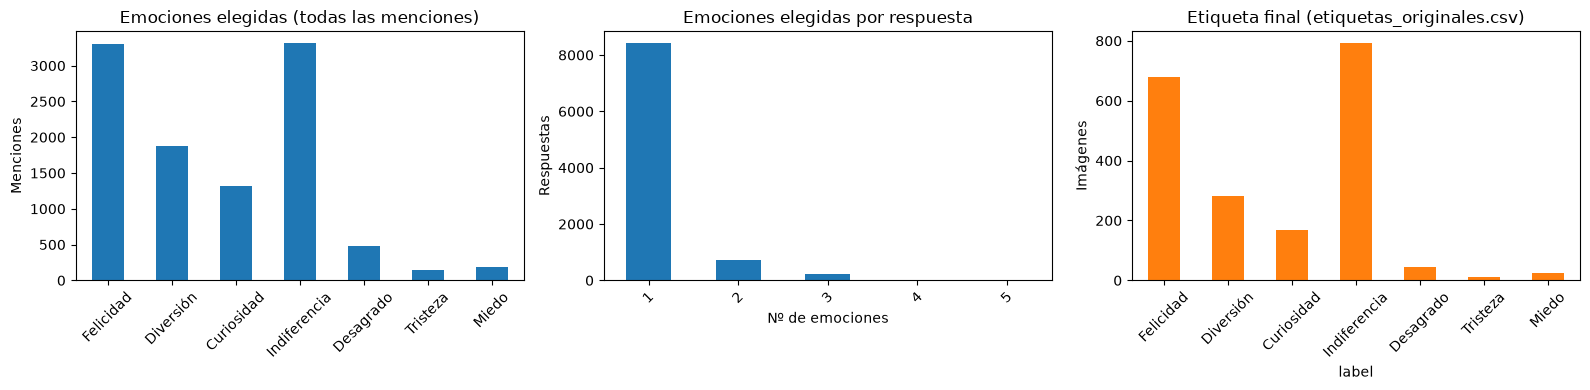

In [5]:
mentions = Counter(e for es in resp['emotions'] for e in es)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
pd.Series({e: mentions[e] for e in EMOTIONS}).plot.bar(ax=axes[0], color='tab:blue')
axes[0].set(title='Emociones elegidas (todas las menciones)', ylabel='Menciones')
resp['n_selected'].value_counts().sort_index().plot.bar(ax=axes[1], color='tab:blue')
axes[1].set(title='Emociones elegidas por respuesta', xlabel='Nº de emociones', ylabel='Respuestas')
lab_counts = labels['label'].value_counts().reindex(EMOTIONS)
lab_counts.plot.bar(ax=axes[2], color='tab:orange')
axes[2].set(title='Etiqueta final (etiquetas_originales.csv)', ylabel='Imágenes')
for ax in axes:
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'distribucion_respuestas.png'), dpi=200)
plt.show()

## 3. Acuerdo en las 7 emociones
Se usa el **α de Krippendorff**, que admite un número distinto de evaluadores por imagen y respuestas faltantes. Como cada persona podía marcar **varias** emociones, se calcula de tres formas:
- **Conjuntos con distancia MASI** (Passonneau, 2006): compara la *respuesta completa*; acuerdo parcial si los conjuntos se solapan.
- **Nominal, solo respuestas de una emoción**: la versión clásica, como control.
- **Por emoción (presente / ausente)**: ¿qué emociones se detectan de forma consistente?

Referencia habitual: α ≥ 0.80 confiable; 0.67–0.80 tentativo; < 0.67 bajo. IC95% por bootstrap sobre imágenes.

In [6]:
def masi(a, b):
    a, b = set(a), set(b)
    if a == b:
        return 0.0
    jaccard = len(a & b) / len(a | b)
    monotonicity = 2 / 3 if (a <= b or b <= a) else (1 / 3 if a & b else 0.0)
    return 1 - jaccard * monotonicity


nominal = lambda a, b: float(a != b)


def coincidence_counts(units):
    # units: lista (una por imagen) con las respuestas de sus evaluadores → matriz imágenes × valores distintos
    values = sorted({v for u in units for v in u}, key=str)
    pos = {v: i for i, v in enumerate(values)}
    counts = np.zeros((len(units), len(values)))
    for i, u in enumerate(units):
        for v in u:
            counts[i, pos[v]] += 1
    return counts, values


def alpha_from_counts(counts, D):
    counts = counts[counts.sum(1) >= 2]
    m = counts.sum(1, keepdims=True)
    w = counts / (m - 1)
    o = w.T @ counts - np.diag(w.sum(0))
    n_c = o.sum(1)
    n = n_c.sum()
    return 1 - (n - 1) * (o * D).sum() / (np.outer(n_c, n_c) * D).sum()


def kripp_alpha(units, distance, n_boot=N_BOOT, seed=0):
    counts, values = coincidence_counts(units)
    D = np.array([[distance(a, b) for b in values] for a in values])
    a = alpha_from_counts(counts, D)
    g = np.random.default_rng(seed)
    boot = [alpha_from_counts(counts[g.integers(0, len(counts), len(counts))], D) for _ in range(n_boot)]
    return a, *np.percentile(boot, [2.5, 97.5])


def units_of(series):
    # Respuestas agrupadas por imagen
    return series.groupby(resp.loc[series.index, 'n']).apply(list).tolist()


single = resp[resp['n_selected'] == 1]
rows = [('Emoción, conjuntos (MASI)', *kripp_alpha(units_of(resp['emotions']), masi)),
        ('Emoción, nominal (solo 1 emoción)', *kripp_alpha(units_of(single['emotions'].str[0]), nominal))]
for e in EMOTIONS:
    rows.append((f'  presencia de {e}', *kripp_alpha(units_of(resp['emotions'].map(lambda x, e=e: e in x)), nominal)))
alpha_emotions = pd.DataFrame(rows, columns=['medida', 'alpha', 'ci95_low', 'ci95_high'])
alpha_emotions.to_csv(os.path.join(OUT, 'alpha_emociones.csv'), index=False)
alpha_emotions

,medida,alpha,ci95_low,ci95_high
0,"Emoción, conjuntos (MASI)",0.105,0.094,0.114
1,"Emoción, nominal (solo 1 emoción)",0.117,0.104,0.129
2,presencia de Felicidad,0.161,0.140,0.181
3,presencia de Diversión,0.105,0.087,0.125
4,presencia de Curiosidad,0.066,0.047,0.088
5,presencia de Indiferencia,0.124,0.104,0.143
6,presencia de Desagrado,0.057,0.033,0.083
7,presencia de Tristeza,0.086,0.033,0.145
8,presencia de Miedo,0.150,0.090,0.213


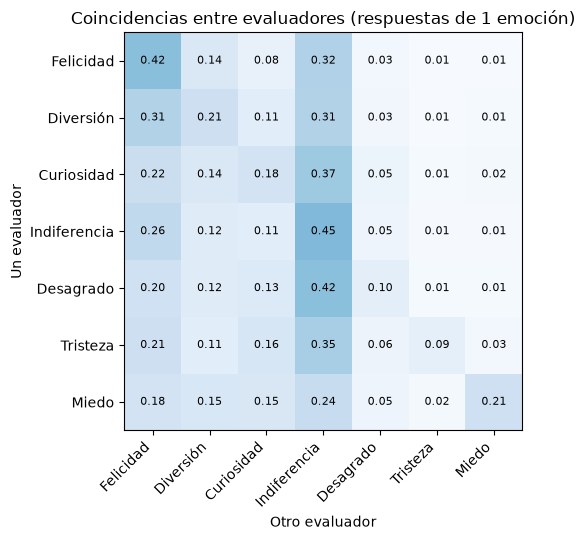

In [7]:
def coincidence_matrix(units, order):
    # P(otro evaluador de la misma imagen responde b | este responde a), a partir de las coincidencias
    counts, values = coincidence_counts(units)
    counts = counts[counts.sum(1) >= 2]
    w = counts / (counts.sum(1, keepdims=True) - 1)
    o = pd.DataFrame(w.T @ counts - np.diag(w.sum(0)), index=values, columns=values)
    o = o.reindex(index=order, columns=order, fill_value=0)
    return o.div(o.sum(axis=1), axis=0), o


def plot_matrix(P, title, ax):
    ax.imshow(P.values, cmap='Blues', vmin=0, vmax=1)
    for i in range(P.shape[0]):
        for j in range(P.shape[1]):
            ax.text(j, i, f'{P.values[i, j]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if P.values[i, j] > .5 else 'black')
    ax.set_xticks(range(P.shape[1]), P.columns, rotation=45, ha='right')
    ax.set_yticks(range(P.shape[0]), P.index)
    ax.set(title=title, xlabel='Otro evaluador', ylabel='Un evaluador')


P_emo, _ = coincidence_matrix(units_of(single['emotions'].str[0]), EMOTIONS)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
plot_matrix(P_emo, 'Coincidencias entre evaluadores (respuestas de 1 emoción)', ax)
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'coincidencias_emociones.png'), dpi=200)
plt.show()

## 4. Acuerdo en valencia y la pregunta de fusionar Negative y Neutral
Cada respuesta se lleva a valencia. Si mezcla valencias (p. ej. *Indiferencia + Desagrado*) se conserva como conjunto para la versión MASI y se excluye de la versión nominal.

La **matriz de coincidencias** responde directamente a la pregunta de fusionar clases: cuando un evaluador responde Negative, ¿qué responden los demás evaluadores de la misma imagen? También se compara el α de tres formulaciones del problema.

,formulación,alpha,ci95_low,ci95_high
0,"3 clases, conjuntos (MASI)",0.128,0.111,0.146
1,"3 clases, nominal",0.138,0.120,0.157
2,2 clases: Positive vs. No positivo (Neutral + ...,0.153,0.131,0.174
3,2 clases: Positive vs. Neutral (sin respuestas...,0.150,0.127,0.172


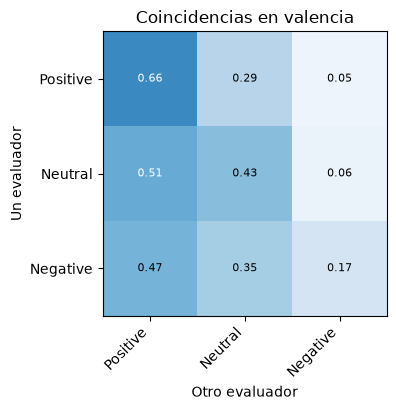

Cuando un evaluador responde Negative, los demás responden: Negative 17%, Neutral 35%, Positive 47%


In [8]:
single_val = resp[resp['valences'].map(len) == 1]['valences'].str[0]
merged = single_val.map(lambda v: 'Positive' if v == 'Positive' else 'No positivo')
pos_neu = single_val[single_val != 'Negative']

rows = [('3 clases, conjuntos (MASI)', *kripp_alpha(units_of(resp['valences']), masi)),
        ('3 clases, nominal', *kripp_alpha(units_of(single_val), nominal)),
        ('2 clases: Positive vs. No positivo (Neutral + Negative)', *kripp_alpha(units_of(merged), nominal)),
        ('2 clases: Positive vs. Neutral (sin respuestas Negative)', *kripp_alpha(units_of(pos_neu), nominal))]
alpha_valence = pd.DataFrame(rows, columns=['formulación', 'alpha', 'ci95_low', 'ci95_high'])
alpha_valence.to_csv(os.path.join(OUT, 'alpha_valencia.csv'), index=False)
display(alpha_valence)

P_val, O_val = coincidence_matrix(units_of(single_val), CLASSES)
fig, ax = plt.subplots(figsize=(4.8, 4.2))
plot_matrix(P_val, 'Coincidencias en valencia', ax)
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'coincidencias_valencia.png'), dpi=200)
plt.show()
neg = P_val.loc['Negative']
print(f"Cuando un evaluador responde Negative, los demás responden: Negative {neg['Negative']:.0%}, "
      f"Neutral {neg['Neutral']:.0%}, Positive {neg['Positive']:.0%}")
P_val.to_csv(os.path.join(OUT, 'coincidencias_valencia.csv'))

## 5. ¿Cómo se obtuvo la etiqueta final y cuánto respaldo tiene?
Para cada imagen se cuentan las **menciones** de cada emoción y se compara con la etiqueta final:
- ¿Es la emoción **más mencionada**? ¿Hubo **empate** en el primer lugar?
- Como la etiqueta se eligió **por emoción** y después se convirtió a valencia, se revisa también si su valencia es la **más votada por valencia**. Pueden no coincidir: si Felicidad y Diversión se reparten los votos positivos, Indiferencia puede ganar por emoción aunque la mayoría haya respondido algo positivo.
- **Respaldo**: % de evaluadores de la imagen que mencionaron la emoción final, o al menos una emoción de su valencia.

Etiqueta final = emoción más mencionada (único primer lugar): 74.2%
Etiqueta final entre las empatadas en primer lugar:         22.9%
Etiqueta final NO es la más mencionada:                    2.9%

Al agregar los votos por VALENCIA (no por emoción):
  la valencia de la etiqueta final es la más votada (sin empate): 81.9%
  empate entre valencias:                                          10.0%
  la valencia de la etiqueta final NO es la más votada:            8.1%
  → por clase final: {'Negative': '28.6% no es la más votada', 'Neutral': '16.8% no es la más votada', 'Positive': '0.6% no es la más votada'}


,imagenes,respaldo_emocion,respaldo_valencia,pct_valencia_sin_mayoria
valence,,,,
Positive,1131,0.610,0.784,0.076
Neutral,792,0.620,0.620,0.351
Negative,77,0.468,0.527,0.532


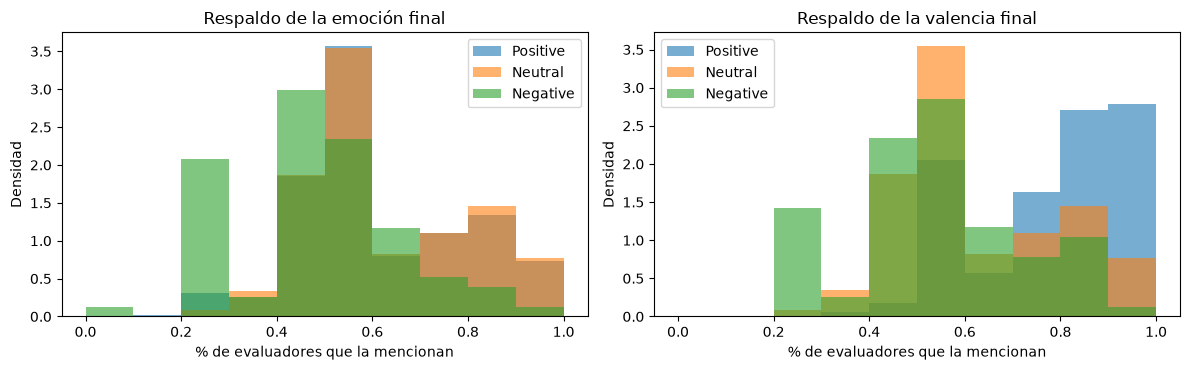

In [9]:
def valence_votes(vs):
    # Un voto por evaluador, repartido entre las valencias que marcó
    return np.array([1 / len(vs) if c in vs else 0.0 for c in CLASSES])


img = []
for n, g in resp.groupby('n'):
    cnt = Counter(e for es in g['emotions'] for e in es)
    vv = np.stack(g['valences'].map(valence_votes).tolist()).sum(0)
    top_val = [c for c, v in zip(CLASSES, vv) if np.isclose(v, vv.max())]
    top = max(cnt.values())
    tops = sorted(e for e, c in cnt.items() if c == top)
    lab = labels.loc[n, 'label']
    val = VALENCE_OF[lab]
    img.append({'n': n, 'image': labels.loc[n, 'image'], 'test': g['test'].iloc[0], 'n_raters': len(g),
                'label': lab, 'valence': val, 'top_emotions': '+'.join(tops), 'tie': len(tops) > 1,
                'label_is_top': lab in tops, 'top_valences': '+'.join(top_val),
                'valence_is_top': val in top_val, 'valence_tie': len(top_val) > 1,
                'support_emotion': g['emotions'].map(lambda es: lab in es).mean(),
                'support_valence': g['valences'].map(lambda vs: val in vs).mean()})
img = pd.DataFrame(img)

print(f"Etiqueta final = emoción más mencionada (único primer lugar): {(img.label_is_top & ~img.tie).mean():.1%}")
print(f"Etiqueta final entre las empatadas en primer lugar:         {(img.label_is_top & img.tie).mean():.1%}")
print(f"Etiqueta final NO es la más mencionada:                    {(~img.label_is_top).mean():.1%}")
print(f"\nAl agregar los votos por VALENCIA (no por emoción):")
print(f"  la valencia de la etiqueta final es la más votada (sin empate): {(img.valence_is_top & ~img.valence_tie).mean():.1%}")
print(f"  empate entre valencias:                                          {img.valence_tie.mean():.1%}")
print(f"  la valencia de la etiqueta final NO es la más votada:            {(~img.valence_is_top).mean():.1%}")
print('  → por clase final:', img.groupby('valence')['valence_is_top'].apply(lambda s: f'{1 - s.mean():.1%} no es la más votada').to_dict())
support = (img.groupby('valence')
           .agg(imagenes=('n', 'size'), respaldo_emocion=('support_emotion', 'mean'),
                respaldo_valencia=('support_valence', 'mean'),
                pct_valencia_sin_mayoria=('support_valence', lambda s: (s <= .5).mean()))
           .reindex(CLASSES))
display(support)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, title in ((axes[0], 'support_emotion', 'emoción final'), (axes[1], 'support_valence', 'valencia final')):
    for c in CLASSES:
        ax.hist(img.loc[img.valence == c, col], bins=np.linspace(0, 1, 11), alpha=.6, label=c, density=True)
    ax.set(title=f'Respaldo de la {title}', xlabel='% de evaluadores que la mencionan', ylabel='Densidad')
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'respaldo_etiqueta_final.png'), dpi=200)
plt.show()

## 6. Un evaluador frente al resto: el techo de cualquier modelo
Para cada respuesta de una sola valencia se compara con la valencia **más votada por los demás evaluadores** de la misma imagen (votos fraccionados si alguien eligió valencias mezcladas; las imágenes con empate entre los demás se excluyen). Es el análogo directo del techo calculado en OASIS (notebook 04).

Además, con la fórmula de Spearman-Brown se estima la confiabilidad aproximada de la etiqueta de consenso según el número de evaluadores por imagen.

In [10]:
records = []
for n, g in resp.groupby('n'):
    votes = np.stack(g['valences'].map(valence_votes).tolist())
    total = votes.sum(0)
    for (_, r), v in zip(g.iterrows(), votes):
        if len(r['valences']) != 1:
            continue
        others = total - v
        if (others == others.max()).sum() > 1:   # empate entre los demás
            continue
        records.append({'n': n, 'test': r['test'], 'rater': r['rater'],
                        'own': CLASSES.index(r['valences'][0]), 'ref': int(others.argmax())})
loo = pd.DataFrame(records)


def agreement(df):
    f1 = f1_score(df['ref'], df['own'], labels=[0, 1, 2], average=None, zero_division=0)
    return {'accuracy': (df['ref'] == df['own']).mean(), 'macro_f1': f1.mean(),
            'kappa': cohen_kappa_score(df['ref'], df['own']), **{f'f1_{c}': v for c, v in zip(CLASSES, f1)}}


ceiling = agreement(loo)
images = loo['n'].unique()
boot = []
for _ in range(N_BOOT):
    pick = rng.choice(images, len(images))
    boot.append(agreement(loo.set_index('n').loc[pick].reset_index()))
boot = pd.DataFrame(boot)
ceiling_tab = pd.DataFrame({'encuestas': ceiling, 'ci95_low': boot.quantile(.025), 'ci95_high': boot.quantile(.975)})
if os.path.exists(OASIS_CEILING):
    ceiling_tab['OASIS (1 anotador)'] = pd.read_csv(OASIS_CEILING, index_col=0)['valor']
ceiling_tab.to_csv(os.path.join(OUT, 'techo_un_evaluador.csv'))
print(f'{len(loo)} respuestas comparadas ({loo.n.nunique()} imágenes sin empate entre los demás evaluadores)')
display(ceiling_tab)

a1 = alpha_valence.loc[1, 'alpha']
k_values = sorted(resp.groupby('n')['rater'].nunique().unique())
print('Confiabilidad aproximada de la etiqueta de consenso (Spearman-Brown sobre α nominal de valencia):')
print({k: round(k * a1 / (1 + (k - 1) * a1), 3) for k in k_values})

7592 respuestas comparadas (1981 imágenes sin empate entre los demás evaluadores)


,encuestas,ci95_low,ci95_high,OASIS (1 anotador)
accuracy,0.628,0.612,0.644,0.703
macro_f1,0.471,0.443,0.496,0.676
kappa,0.242,0.212,0.272,0.532
f1_Positive,0.731,0.714,0.746,0.773
f1_Neutral,0.478,0.449,0.506,0.507
f1_Negative,0.205,0.131,0.278,0.748


Confiabilidad aproximada de la etiqueta de consenso (Spearman-Brown sobre α nominal de valencia):
{np.int64(3): np.float64(0.325), np.int64(4): np.float64(0.391), np.int64(5): np.float64(0.445), np.int64(6): np.float64(0.49), np.int64(7): np.float64(0.529)}


## 7. Acuerdo por test y por evaluador
Permite detectar encuestas con poco acuerdo y evaluadores que respondieron de forma muy distinta al resto (por ejemplo, al azar).

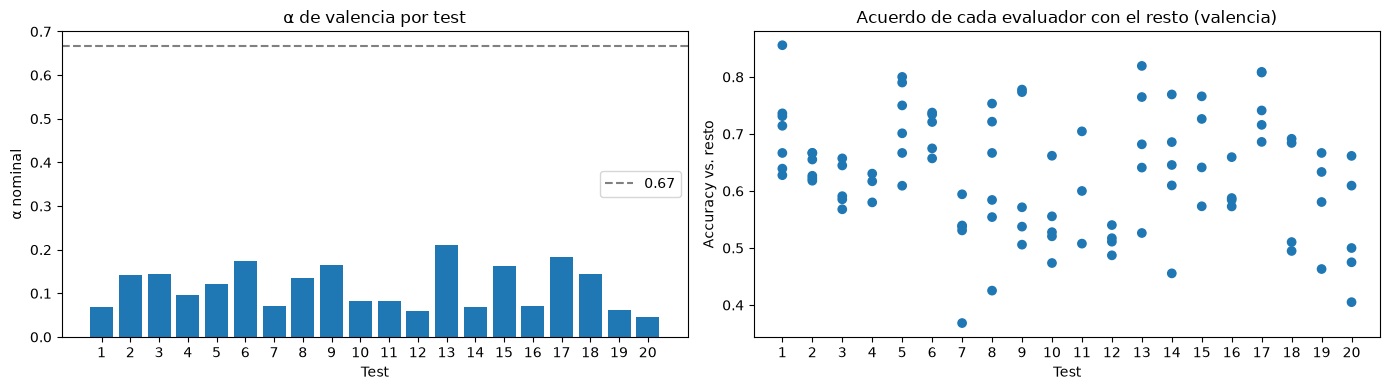

test,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
evaluadores,7,6,5,3,6,5,5,6,5,5,3,4,5,5,4,4,5,4,4,5
alpha_valencia,0.068,0.141,0.144,0.095,0.120,0.175,0.071,0.136,0.164,0.081,0.083,0.059,0.210,0.068,0.163,0.071,0.183,0.145,0.062,0.045
ci95_valencia,"[0.02, 0.11]","[0.07, 0.20]","[0.07, 0.21]","[-0.01, 0.18]","[0.01, 0.20]","[0.08, 0.26]","[0.02, 0.13]","[0.08, 0.19]","[0.09, 0.24]","[0.01, 0.15]","[-0.02, 0.18]","[-0.04, 0.13]","[0.14, 0.29]","[-0.01, 0.14]","[0.07, 0.27]","[-0.02, 0.13]","[0.09, 0.27]","[0.04, 0.22]","[-0.01, 0.11]","[-0.01, 0.11]"
alpha_emocion_MASI,0.071,0.113,0.090,0.116,0.080,0.116,0.089,0.117,0.120,0.053,0.097,0.060,0.134,0.043,0.113,0.040,0.116,0.148,0.052,0.028


Evaluadores atípicos (acuerdo muy por debajo del resto):


,test,rater,respuestas,acuerdo_con_resto,atipico


In [11]:
rows = []
for k, g in resp.groupby('test'):
    sv = g[g['valences'].map(len) == 1]
    a_val = kripp_alpha(sv['valences'].str[0].groupby(sv['n']).apply(list).tolist(), nominal, n_boot=200)
    a_emo = kripp_alpha(g['emotions'].groupby(g['n']).apply(list).tolist(), masi, n_boot=200)
    rows.append({'test': k, 'evaluadores': g['rater'].nunique(), 'alpha_valencia': a_val[0],
                 'ci95_valencia': f'[{a_val[1]:.2f}, {a_val[2]:.2f}]', 'alpha_emocion_MASI': a_emo[0]})
by_test = pd.DataFrame(rows)
by_test.to_csv(os.path.join(OUT, 'alpha_por_test.csv'), index=False)

by_rater = (loo.groupby(['test', 'rater'])
            .apply(lambda d: pd.Series({'respuestas': len(d), 'acuerdo_con_resto': (d.own == d.ref).mean()}))
            .reset_index())
z = (by_rater['acuerdo_con_resto'] - by_rater['acuerdo_con_resto'].median()) / \
    (1.4826 * (by_rater['acuerdo_con_resto'] - by_rater['acuerdo_con_resto'].median()).abs().median())
by_rater['atipico'] = z < -2.5
by_rater.to_csv(os.path.join(OUT, 'acuerdo_por_evaluador.csv'), index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(by_test['test'], by_test['alpha_valencia'], color='tab:blue')
axes[0].axhline(0.667, ls='--', color='gray', label='0.67')
axes[0].set(title='α de valencia por test', xlabel='Test', ylabel='α nominal', xticks=by_test['test'])
axes[0].legend()
colors = np.where(by_rater['atipico'], 'tab:red', 'tab:blue')
axes[1].scatter(by_rater['test'], by_rater['acuerdo_con_resto'], c=colors)
axes[1].set(title='Acuerdo de cada evaluador con el resto (valencia)', xlabel='Test',
            ylabel='Accuracy vs. resto', xticks=by_test['test'])
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'acuerdo_por_test_y_evaluador.png'), dpi=200)
plt.show()
display(by_test.set_index('test').T)
print('Evaluadores atípicos (acuerdo muy por debajo del resto):')
display(by_rater[by_rater['atipico']])

## 8. Distribución de votos por imagen (etiquetas "blandas")
Se guarda, para cada imagen, la fracción de votos de cada emoción y de cada valencia (votos fraccionados cuando alguien eligió varias), junto con la etiqueta final y su respaldo. Este archivo permite:
- **entrenar con etiquetas blandas** (la distribución de votos en lugar de una sola clase), que incorpora la ambigüedad real de cada imagen;
- **filtrar o ponderar** las imágenes con poco consenso;
- **evaluar** los modelos contra la distribución de votos.

In [12]:
def emotion_votes(es):
    return pd.Series({e: 1 / len(es) if e in es else 0.0 for e in EMOTIONS})


emo_frac = resp.groupby('n')['emotions'].apply(lambda s: pd.concat([emotion_votes(e) for e in s], axis=1).mean(axis=1)).unstack()
val_frac = resp.groupby('n')['valences'].apply(lambda s: pd.DataFrame([valence_votes(v) for v in s], columns=CLASSES).mean()).unstack()
soft = (img.set_index('n')
        .join(emo_frac.add_prefix('p_'))
        .join(val_frac.add_prefix('p_')))
soft.to_csv(os.path.join(OUT, 'votos_por_imagen.csv'))
soft[['image', 'n_raters', 'label', 'valence', 'support_valence', 'p_Positive', 'p_Neutral', 'p_Negative']].head()

,image,n_raters,label,valence,support_valence,p_Positive,p_Neutral,p_Negative
n,,,,,,,,
1,1.jpg,7,Indiferencia,Neutral,0.429,0.571,0.429,0.000
2,2.jpg,7,Indiferencia,Neutral,0.714,0.286,0.571,0.143
3,3.jpg,7,Diversión,Positive,0.857,0.857,0.143,0.000
4,4.jpg,7,Indiferencia,Neutral,0.286,0.571,0.286,0.143
5,5.jpg,7,Felicidad,Positive,1.000,1.000,0.000,0.000


## 9. Comparación con `etiquetas_originales.csv`
Se compara la etiqueta original de cada imagen con lo que indica la encuesta:
1. **Calidad del archivo**: caracteres invisibles, imágenes faltantes.
2. **Distribución de clases**: original frente a la mayoría de la encuesta.
3. **Matrices de confusión** entre la etiqueta original y la emoción más mencionada, y entre la valencia original y la **valencia más votada** (votos fraccionados; los empates se muestran aparte).
4. **Discrepancias**: imágenes cuya valencia original no es la más votada, ordenadas por margen. Se guardan en `discrepancias_valencia.csv`.

In [13]:
# 1) Calidad del archivo
raw_labels = pd.read_csv(LABELS_CSV, encoding='utf-8-sig', dtype=str)
raw_labels['n'] = raw_labels['image'].str.extract(r'(\d+)', expand=False).astype(int)
dirty = raw_labels['label'] != raw_labels['label'].map(clean)
print(f"{len(raw_labels)} filas, {raw_labels['image'].nunique()} imágenes distintas, números {raw_labels.n.min()}–{raw_labels.n.max()}")
print(f"Etiquetas con caracteres invisibles o espacios sobrantes: {dirty.sum()} ({dirty.mean():.1%})")
print('  tipos:', dict(Counter(repr(x) for x in raw_labels.loc[dirty, 'label']).most_common()))
print('  por test:', {int(k): int(v) for k, v in dirty.groupby((raw_labels['n'] - 1) // 100 + 1).sum().items() if v})
print('  (pipeline.load_labels los limpia, así que el entrenamiento no se vio afectado)')
img_dir = os.path.join('images_or')
if os.path.isdir(img_dir):
    missing = [f for f in raw_labels['image'] if not os.path.exists(os.path.join(img_dir, f))]
    print(f'Imágenes listadas que no están en {img_dir}/: {len(missing)}')

2000 filas, 2000 imágenes distintas, números 1–2000
Etiquetas con caracteres invisibles o espacios sobrantes: 553 (27.7%)
  tipos: {"'Indiferencia\\ufeff'": 234, "'Felicidad '": 155, "'Felicidad\\xa0'": 141, "'Diversión '": 22, "'Desagrado '": 1}
  por test: {6: 59, 7: 67, 8: 82, 9: 79, 10: 90, 11: 34, 12: 28, 13: 28, 14: 37, 15: 42, 16: 1, 17: 3, 19: 2, 20: 1}
  (pipeline.load_labels los limpia, así que el entrenamiento no se vio afectado)
Imágenes listadas que no están en images_or/: 0


In [14]:
# Etiquetas del CSV que no coinciden con la clave de la encuesta: posibles errores de transcripción
mention_counts = resp.groupby('n')['emotions'].apply(lambda s: Counter(e for es in s for e in es))
check = []
for n, r in keys[~keys['label_in_key']].iterrows():
    votes = {e: int(v) for e, v in mention_counts.loc[n].items() if v > 0}
    key_votes = max(votes.get(e, 0) for e in r['key']) if r['key'] else 0
    check.append({'image': f'{n}.jpg', 'clave_encuesta': '+'.join(r['key']) if r['key'] else None,
                  'etiqueta_csv': r['label'], 'votos_clave': key_votes,
                  'votos_etiqueta_csv': votes.get(r['label'], 0), 'votos': votes,
                  'probable_error_csv': votes.get(r['label'], 0) < key_votes})
check = pd.DataFrame(check)
check.to_csv(os.path.join(OUT, 'etiquetas_csv_distintas_de_la_clave.csv'), index=False)
print(f"{len(check)} imágenes cuya etiqueta en el CSV no está en la clave de la encuesta; "
      f"en {check['probable_error_csv'].sum()} la clave tenía más votos (probable error de transcripción)")
check

8 imágenes cuya etiqueta en el CSV no está en la clave de la encuesta; en 7 la clave tenía más votos (probable error de transcripción)


,image,clave_encuesta,etiqueta_csv,votos_clave,votos_etiqueta_csv,votos,probable_error_csv
0,23.jpg,Miedo,Felicidad,3,2,"{'Indiferencia': 1, 'Felicidad': 2, 'Diversión...",True
1,48.jpg,Indiferencia,Diversión,5,1,"{'Indiferencia': 5, 'Diversión': 1, 'Desagrado...",True
2,49.jpg,Diversión,Indiferencia,4,0,"{'Felicidad': 2, 'Diversión': 4, 'Curiosidad': 2}",True
3,54.jpg,Curiosidad,Indiferencia,4,2,"{'Indiferencia': 2, 'Felicidad': 1, 'Diversión...",True
4,89.jpg,Indiferencia,Felicidad,2,1,"{'Indiferencia': 2, 'Felicidad': 1, 'Diversión...",True
5,264.jpg,Desagrado,Tristeza,3,0,"{'Indiferencia': 1, 'Desagrado': 3, 'Miedo': 2}",True
6,508.jpg,Indiferencia,Curiosidad,2,3,"{'Indiferencia': 2, 'Diversión': 1, 'Curiosida...",False
7,794.jpg,Indiferencia,Diversión,3,0,"{'Indiferencia': 3, 'Curiosidad': 2}",True


Distribución de clases de valencia


,original,mayoría encuesta
Positive,1131,1227
Neutral,792,531
Negative,77,42
Empate,0,200


Valencia original (filas) vs. valencia más votada en la encuesta (columnas)


survey_valence,Positive,Neutral,Negative,Empate
valence,,,,
Positive,1074,4,3,50
Neutral,131,527,2,132
Negative,22,0,37,18


Sin contar empates (1800 imágenes): coinciden 91.0%; κ de Cohen = 0.813
Recall de la etiqueta original respecto de la mayoría de la encuesta (por clase de la encuesta): {'Positive': '87.5%', 'Neutral': '99.2%', 'Negative': '88.1%'}

Emoción original (filas) vs. emoción más mencionada (columnas), 1534 imágenes sin empate; coinciden 96.8%


top_emotions,Felicidad,Diversión,Curiosidad,Indiferencia,Desagrado,Tristeza,Miedo
label,,,,,,,
Felicidad,562,3,1,0,0,0,1
Diversión,5,178,2,3,1,0,0
Curiosidad,4,1,100,2,3,1,0
Indiferencia,10,5,3,613,0,0,0
Desagrado,0,0,0,1,16,1,0
Tristeza,0,0,0,0,1,4,0
Miedo,0,0,0,1,0,0,12


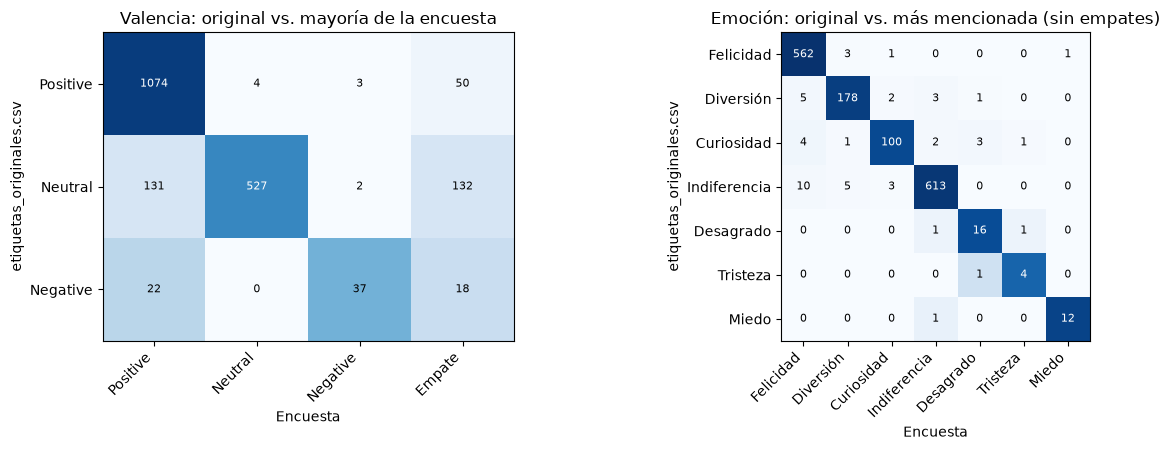

In [15]:
# 2) y 3) Comparación de clases
cmp = img.set_index('n')[['image', 'test', 'n_raters', 'label', 'valence', 'top_emotions', 'tie',
                          'label_is_top', 'support_emotion', 'support_valence']].join(val_frac.add_prefix('p_'))
vv = cmp[[f'p_{c}' for c in CLASSES]].to_numpy()
is_top = np.isclose(vv, vv.max(1, keepdims=True))
cmp['survey_valence'] = np.where(is_top.sum(1) > 1, 'Empate', np.array(CLASSES)[vv.argmax(1)])
own = vv[np.arange(len(cmp)), [CLASSES.index(v) for v in cmp['valence']]]
other = np.where(np.eye(3, dtype=bool)[[CLASSES.index(v) for v in cmp['valence']]], -np.inf, vv).max(1)
cmp['margin'] = own - other          # > 0: la valencia original es la más votada; < 0: otra valencia ganó

dist = pd.DataFrame({'original': cmp['valence'].value_counts(),
                     'mayoría encuesta': cmp['survey_valence'].value_counts()}).reindex(CLASSES + ['Empate']).fillna(0).astype(int)
print('Distribución de clases de valencia')
display(dist)

print('Valencia original (filas) vs. valencia más votada en la encuesta (columnas)')
conf_val = pd.crosstab(cmp['valence'], cmp['survey_valence']).reindex(index=CLASSES, columns=CLASSES + ['Empate'], fill_value=0)
display(conf_val)
no_tie = cmp[cmp['survey_valence'] != 'Empate']
print(f"Sin contar empates ({len(no_tie)} imágenes): coinciden {(no_tie.valence == no_tie.survey_valence).mean():.1%}; "
      f"κ de Cohen = {cohen_kappa_score(no_tie.valence, no_tie.survey_valence):.3f}")
print('Recall de la etiqueta original respecto de la mayoría de la encuesta (por clase de la encuesta):',
      {c: f"{(no_tie.loc[no_tie.survey_valence == c, 'valence'] == c).mean():.1%}" for c in CLASSES})

unique_top = cmp[~cmp['tie']]
conf_emo = pd.crosstab(unique_top['label'], unique_top['top_emotions']).reindex(index=EMOTIONS, columns=EMOTIONS, fill_value=0)
print(f"\nEmoción original (filas) vs. emoción más mencionada (columnas), {len(unique_top)} imágenes sin empate; "
      f"coinciden {(unique_top.label == unique_top.top_emotions).mean():.1%}")
display(conf_emo)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, M, title in ((axes[0], conf_val, 'Valencia: original vs. mayoría de la encuesta'),
                     (axes[1], conf_emo, 'Emoción: original vs. más mencionada (sin empates)')):
    P = M.div(M.sum(axis=1).replace(0, 1), axis=0)
    ax.imshow(P.values, cmap='Blues', vmin=0, vmax=1)
    for a in range(M.shape[0]):
        for b in range(M.shape[1]):
            ax.text(b, a, f'{M.values[a, b]}', ha='center', va='center', fontsize=8,
                    color='white' if P.values[a, b] > .5 else 'black')
    ax.set_xticks(range(M.shape[1]), M.columns, rotation=45, ha='right')
    ax.set_yticks(range(M.shape[0]), M.index)
    ax.set(title=title, xlabel='Encuesta', ylabel='etiquetas_originales.csv')
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'comparacion_etiquetas_originales.png'), dpi=200)
plt.show()

In [16]:
# 4) Discrepancias de valencia
disc = cmp[(cmp['survey_valence'] != 'Empate') & (cmp['valence'] != cmp['survey_valence'])].sort_values('margin')
cols = ['image', 'test', 'n_raters', 'label', 'valence', 'survey_valence', 'p_Positive', 'p_Neutral', 'p_Negative', 'margin']
disc[cols].to_csv(os.path.join(OUT, 'discrepancias_valencia.csv'))
cmp.to_csv(os.path.join(OUT, 'comparacion_etiquetas.csv'))
print(f"{len(disc)} imágenes ({len(disc) / len(cmp):.1%}) cuya valencia original no es la más votada; "
      f"además {(cmp.survey_valence == 'Empate').sum()} con empate entre valencias.")
print('Cambios de clase si se usara la valencia más votada:')
display(pd.crosstab(disc['valence'], disc['survey_valence']).rename_axis(index='original', columns='mayoría'))
print('Las 10 discrepancias más claras:')
disc[cols].head(10)

162 imágenes (8.1%) cuya valencia original no es la más votada; además 200 con empate entre valencias.
Cambios de clase si se usara la valencia más votada:


mayoría,Negative,Neutral,Positive
original,,,
Negative,0,0,22
Neutral,2,0,131
Positive,3,4,0


Las 10 discrepancias más claras:


,image,test,n_raters,label,valence,survey_valence,p_Positive,p_Neutral,p_Negative,margin
n,,,,,,,,,,
49,49.jpg,1,7,Indiferencia,Neutral,Positive,1.000,0.000,0.000,-1.000
1514,1514.jpg,16,4,Indiferencia,Neutral,Positive,0.750,0.250,0.000,-0.500
48,48.jpg,1,7,Diversión,Positive,Neutral,0.143,0.643,0.214,-0.500
54,54.jpg,1,7,Indiferencia,Neutral,Positive,0.714,0.286,0.000,-0.429
42,42.jpg,1,7,Indiferencia,Neutral,Positive,0.714,0.286,0.000,-0.429
425,425.jpg,5,5,Miedo,Negative,Positive,0.600,0.200,0.200,-0.400
836,836.jpg,9,5,Tristeza,Negative,Positive,0.600,0.200,0.200,-0.400
636,636.jpg,7,5,Desagrado,Negative,Positive,0.600,0.200,0.200,-0.400
936,936.jpg,10,5,Indiferencia,Neutral,Positive,0.600,0.200,0.200,-0.400


### 9b. ¿La etiqueta de cada imagen está respaldada por la encuesta?
Cada imagen se clasifica según la valencia de su etiqueta en `etiquetas_originales.csv`:
- **✓ Respaldada**: su valencia es la más votada, sin empate.
- **= Empate**: su valencia empata en el primer lugar con otra.
- **✗ Contradicha**: otra valencia recibió más votos.

**Figura 1.** Una columna por clase del CSV. Cada línea vertical es una imagen; las imágenes están ordenadas por el porcentaje de votos que respaldan su valencia, que va en la base. La línea punteada marca el 50%; la franja inferior indica el estado de cada imagen.

**Figura 2.** Número de imágenes en cada estado, por clase y por test.

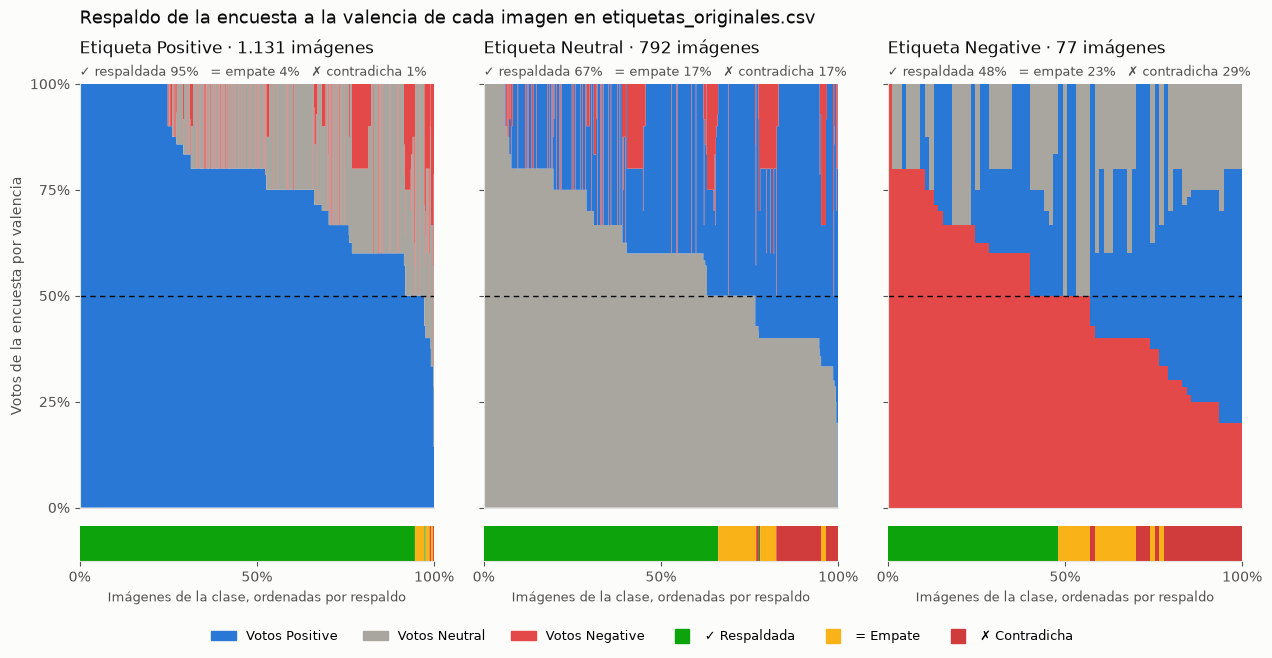

In [17]:
SURFACE, INK, INK2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
VAL_COLOR = {'Positive': '#2a78d6', 'Neutral': '#a8a69f', 'Negative': '#e34948'}   # par divergente + punto medio gris
STATUS = {'Respaldada': ('#0ca30c', '✓'), 'Empate': ('#fab219', '='), 'Contradicha': ('#d03b3b', '✗')}
plt.rcParams.update({'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.titlecolor': INK, 'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE})

cmp['status'] = np.select([cmp['valence'] == cmp['survey_valence'],
                           (cmp['survey_valence'] == 'Empate') & (cmp['margin'] >= 0)],
                          ['Respaldada', 'Empate'], 'Contradicha')
cmp['p_label'] = [cmp.loc[n, f'p_{v}'] for n, v in zip(cmp.index, cmp['valence'])]

fig = plt.figure(figsize=(15, 6.2))
gs = fig.add_gridspec(2, 3, height_ratios=[12, 1], hspace=0.08, wspace=0.14)
for col, cls in enumerate(CLASSES):
    d = cmp[cmp['valence'] == cls].sort_values(['p_label', 'margin'], ascending=False)
    x = np.arange(len(d) + 1) / len(d) * 100
    order = [cls] + [c for c in CLASSES if c != cls]          # la valencia de la etiqueta va en la base
    ax = fig.add_subplot(gs[0, col])
    bottom = np.zeros(len(d))
    for c in order:
        top = bottom + d[f'p_{c}'].to_numpy()
        ax.stairs(top, x, baseline=bottom, fill=True, color=VAL_COLOR[c], linewidth=0,
                  label=c + (' (etiqueta)' if c == cls else ''))
        bottom = top
    ax.axhline(0.5, color=INK, lw=1, ls=(0, (4, 3)))
    ax.set(xlim=(0, 100), ylim=(0, 1))
    ax.set_xticks([])
    ax.set_yticks([0, .25, .5, .75, 1], ['0%', '25%', '50%', '75%', '100%'] if col == 0 else [])
    if col == 0:
        ax.set_ylabel('Votos de la encuesta por valencia')
    shares = d['status'].value_counts(normalize=True).reindex(STATUS, fill_value=0)
    ax.set_title(f'Etiqueta {cls} · {len(d):,} imágenes'.replace(',', '.'), loc='left', fontsize=12, pad=22)
    ax.text(0, 1.012, '   '.join(f'{STATUS[s][1]} {s.lower()} {shares[s]:.0%}' for s in STATUS),
            transform=ax.transAxes, fontsize=9, color=INK2, va='bottom')
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    strip = fig.add_subplot(gs[1, col])
    for s, (color, _) in STATUS.items():
        m = (d['status'] == s).to_numpy()
        strip.stairs(m.astype(float), x, fill=True, color=color, linewidth=0)
    strip.set(xlim=(0, 100), ylim=(0, 1), yticks=[])
    strip.set_xticks([0, 50, 100], ['0%', '50%', '100%'])
    strip.set_xlabel('Imágenes de la clase, ordenadas por respaldo', fontsize=9)
    for side in ('top', 'right', 'left'):
        strip.spines[side].set_visible(False)

val_handles = [plt.Rectangle((0, 0), 1, 1, color=VAL_COLOR[c]) for c in CLASSES]
st_handles = [plt.Line2D([], [], marker='s', ls='', markersize=10, color=STATUS[s][0]) for s in STATUS]
fig.legend(val_handles + st_handles,
           [f'Votos {c}' for c in CLASSES] + [f'{STATUS[s][1]} {s}' for s in STATUS],
           loc='lower center', ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.04), fontsize=9)
fig.suptitle('Respaldo de la encuesta a la valencia de cada imagen en etiquetas_originales.csv',
             x=0.125, y=1.0, ha='left', fontsize=13, color=INK)
plt.savefig(os.path.join(OUT, 'acuerdo_por_imagen.png'), dpi=200, bbox_inches='tight', facecolor=SURFACE)
plt.show()

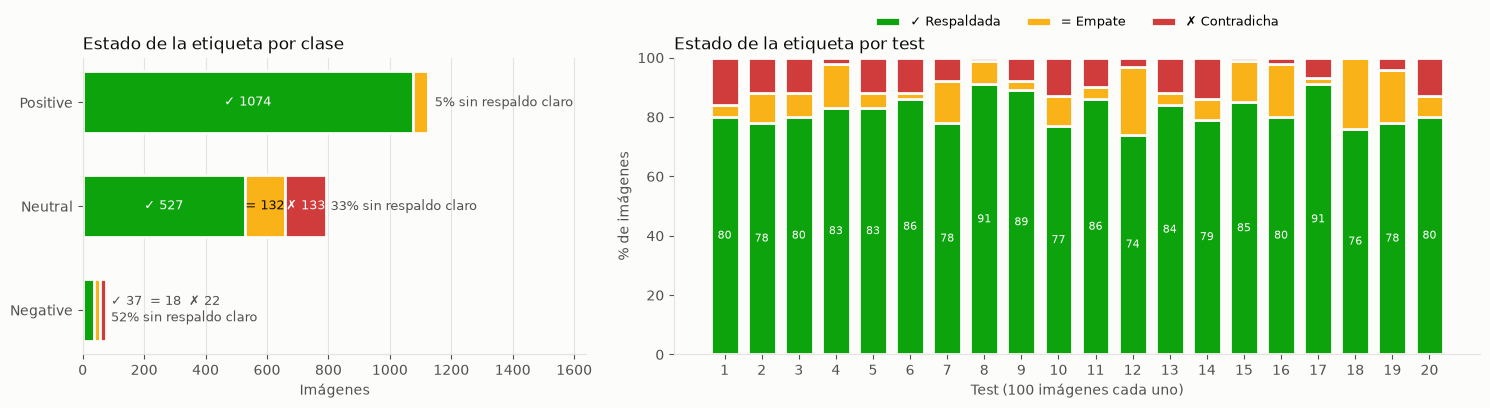

status,Respaldada,Empate,Contradicha,total
valence,,,,
Positive,1074,50,7,1131
Neutral,527,132,133,792
Negative,37,18,22,77


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={'width_ratios': [1, 1.6]})

# Por clase: barras horizontales apiladas (número de imágenes)
ax = axes[0]
counts = pd.crosstab(cmp['valence'], cmp['status']).reindex(index=CLASSES[::-1], columns=list(STATUS), fill_value=0)
left = np.zeros(len(counts))
for s, (color, icon) in STATUS.items():
    v = counts[s].to_numpy()
    ax.barh(counts.index, v, left=left, color=color, height=0.6, edgecolor=SURFACE, linewidth=2)
    for y, (l, w) in enumerate(zip(left, v)):
        if w >= 60:     # etiqueta dentro solo si cabe
            ax.text(l + w / 2, y, f'{icon} {w}', ha='center', va='center', fontsize=9,
                    color='white' if s != 'Empate' else INK)
    left += v
for y, tot in enumerate(counts.sum(axis=1)):
    r = counts.iloc[y]
    pct = r[['Empate', 'Contradicha']].sum() / tot
    det = '' if tot >= 300 else f"✓ {r['Respaldada']}  = {r['Empate']}  ✗ {r['Contradicha']}\n"
    ax.text(tot + 15, y, f'{det}{pct:.0%} sin respaldo claro', va='center', fontsize=9, color=INK2)
ax.set(xlabel='Imágenes', xlim=(0, counts.sum(axis=1).max() * 1.45))
ax.set_title('Estado de la etiqueta por clase', loc='left', fontsize=12)
ax.grid(axis='x', color=GRID, lw=0.8)
ax.set_axisbelow(True)

# Por test: columnas apiladas (porcentaje de imágenes)
ax = axes[1]
by_t = pd.crosstab(cmp['test'], cmp['status'], normalize='index').reindex(columns=list(STATUS), fill_value=0) * 100
bottom = np.zeros(len(by_t))
for s, (color, icon) in STATUS.items():
    ax.bar(by_t.index, by_t[s], bottom=bottom, color=color, width=0.75, edgecolor=SURFACE, linewidth=2,
           label=f'{icon} {s}')
    bottom += by_t[s].to_numpy()
for t, v in by_t['Respaldada'].items():
    ax.text(t, v / 2, f'{v:.0f}', ha='center', va='center', fontsize=8, color='white')
ax.set(xticks=by_t.index, ylim=(0, 100), xlabel='Test (100 imágenes cada uno)', ylabel='% de imágenes')
ax.set_title('Estado de la etiqueta por test', loc='left', fontsize=12)
ax.legend(ncol=3, frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.06), fontsize=9)
for a in axes:
    for side in ('top', 'right'):
        a.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'estado_etiquetas.png'), dpi=200, bbox_inches='tight', facecolor=SURFACE)
plt.show()
plt.rcdefaults()
cmp[['image', 'test', 'n_raters', 'label', 'valence', 'survey_valence', 'p_Positive', 'p_Neutral', 'p_Negative',
     'status']].to_csv(os.path.join(OUT, 'estado_por_imagen.csv'))
display(counts.iloc[::-1].assign(total=counts.iloc[::-1].sum(axis=1)))

### 9c. Acuerdo de Fleiss por imagen
"Respaldada" solo indica que la valencia de la etiqueta fue la más votada, no cuánto coincidieron los evaluadores. Para medir eso se usa el **acuerdo por imagen de Fleiss**:

$$P_i = \frac{\sum_k n_{ik}(n_{ik}-1)}{n_i(n_i-1)}$$

Es la proporción de pares de evaluadores de la imagen *i* que dieron la misma respuesta. Cada respuesta es el conjunto de valencias que marcó el evaluador, así que "Positive+Neutral" cuenta como una categoría propia.
- $P_e = \sum_k p_k^2$ es el acuerdo esperado por azar, según la frecuencia global de cada respuesta.
- $\kappa_i = (P_i - P_e)/(1 - P_e)$ es el aporte de la imagen al κ de Fleiss: su promedio sobre todas las imágenes es exactamente el κ global.
- `fleiss_Pi_masi` es una variante que da crédito parcial a conjuntos que se solapan (1 − MASI), coherente con el α de la sección 4.

**Niveles:**
- **Unánime:** $P_i = 1$.
- **Sobre el azar:** $P_e < P_i < 1$.
- **No supera el azar:** $P_i \le P_e$.

Como referencia, con 5 evaluadores: 4 contra 1 da $P_i = 0{,}6$ y 3 contra 2 da $P_i = 0{,}4$.

In [19]:
from itertools import combinations

key = lambda vs: '+'.join(vs)                      # respuesta = conjunto de valencias marcadas
answers = resp.groupby('n')['valences'].apply(list)
freq = pd.Series([key(v) for u in answers for v in u]).value_counts(normalize=True)
P_e = (freq ** 2).sum()
P_e_masi = sum(freq[a] * freq[b] * (1 - masi(a.split('+'), b.split('+'))) for a in freq.index for b in freq.index)

def fleiss_Pi(u):
    n_k = np.array(list(Counter(key(v) for v in u).values()))
    return (n_k * (n_k - 1)).sum() / (len(u) * (len(u) - 1))

cmp['fleiss_Pi'] = answers.map(fleiss_Pi)
cmp['fleiss_Pi_masi'] = answers.map(lambda u: np.mean([1 - masi(a, b) for a, b in combinations(u, 2)]))
cmp['kappa_i'] = (cmp['fleiss_Pi'] - P_e) / (1 - P_e)
NIVELES = ['No supera el azar', 'Sobre el azar', 'Unánime']
cmp['nivel_acuerdo'] = pd.Categorical(np.select([np.isclose(cmp['fleiss_Pi'], 1), cmp['fleiss_Pi'] > P_e],
                                                NIVELES[:0:-1], NIVELES[0]), NIVELES, ordered=True)

print('Frecuencia global de cada respuesta:', freq.round(3).to_dict())
print(f"P_e (azar) = {P_e:.3f}   ·   P̄ = {cmp['fleiss_Pi'].mean():.3f}   →   κ de Fleiss = {cmp['kappa_i'].mean():.3f}")
print(f"Variante MASI: P_e = {P_e_masi:.3f}, P̄ = {cmp['fleiss_Pi_masi'].mean():.3f}, "
      f"κ = {(cmp['fleiss_Pi_masi'].mean() - P_e_masi) / (1 - P_e_masi):.3f}")
print('Evaluadores por imagen:', cmp['n_raters'].value_counts().sort_index().to_dict())

tab = pd.crosstab([cmp['valence'], cmp['status']], cmp['nivel_acuerdo']).reindex(
    pd.MultiIndex.from_product([CLASSES, list(STATUS)]), fill_value=0)
tab['total'] = tab.sum(axis=1)
display(tab)
display(pd.crosstab(cmp['valence'], cmp['nivel_acuerdo'], margins=True, margins_name='Total').reindex(CLASSES + ['Total']))

Frecuencia global de cada respuesta: {'Positive': 0.578, 'Neutral': 0.335, 'Negative': 0.061, 'Neutral+Negative': 0.01, 'Positive+Negative': 0.008, 'Positive+Neutral': 0.006, 'Positive+Neutral+Negative': 0.001}
P_e (azar) = 0.450   ·   P̄ = 0.515   →   κ de Fleiss = 0.118
Variante MASI: P_e = 0.461, P̄ = 0.526, κ = 0.121
Evaluadores por imagen: {3: 200, 4: 500, 5: 1110, 6: 90, 7: 100}


nivel_acuerdo         No supera el azar  Sobre el azar  Unánime  total
Positive Respaldada                 298            495      281   1074
         Empate                      50              0        0     50
         Contradicha                  7              0        0      7
Neutral  Respaldada                 285            195       47    527
         Empate                     132              0        0    132
         Contradicha                125              7        1    133
Negative Respaldada                  25             11        1     37
         Empate                      18              0        0     18
         Contradicha                 22              0        0     22

nivel_acuerdo,No supera el azar,Sobre el azar,Unánime,Total
valence,,,,
Positive,355,495,281,1131
Neutral,542,202,48,792
Negative,65,11,1,77
Total,962,708,330,2000


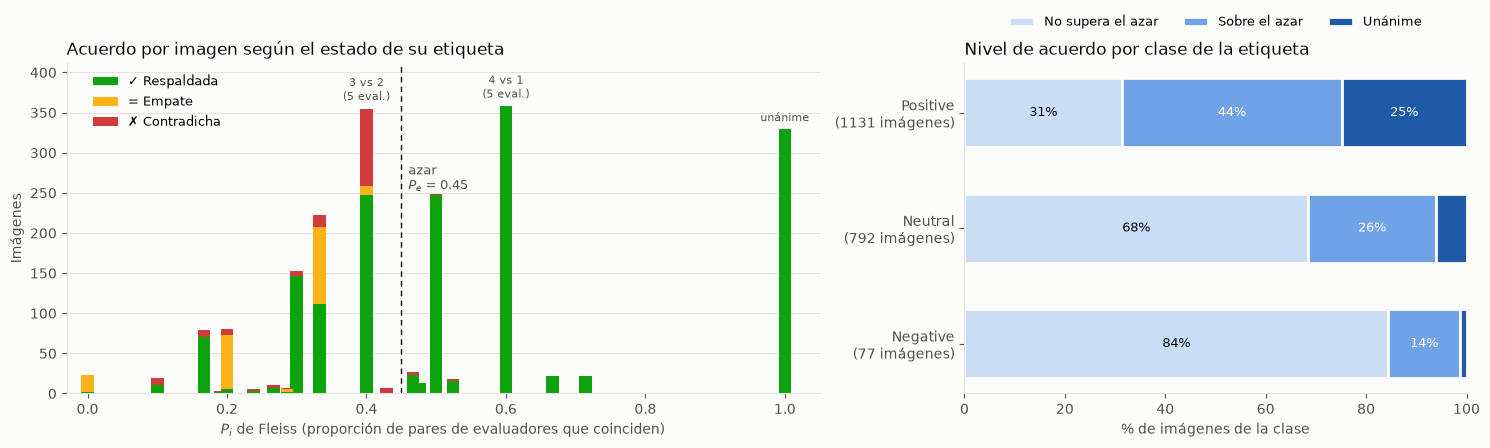

In [20]:
plt.rcParams.update({'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.titlecolor': INK, 'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE})
NIVEL_COLOR = dict(zip(NIVELES, ['#c9ddf5', '#6fa3e6', '#1f5aa6']))     # secuencial, un solo tono
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={'width_ratios': [1.5, 1]})

# Distribución de P_i, apilada por estado de la etiqueta
ax = axes[0]
vals = np.sort(cmp['fleiss_Pi'].round(3).unique())
by_v = pd.crosstab(cmp['fleiss_Pi'].round(3), cmp['status']).reindex(index=vals, columns=list(STATUS), fill_value=0)
bottom = np.zeros(len(vals))
for s, (color, icon) in STATUS.items():
    ax.bar(vals, by_v[s], bottom=bottom, width=0.018, color=color, label=f'{icon} {s}')
    bottom += by_v[s].to_numpy()
ax.axvline(P_e, color=INK, lw=1, ls=(0, (4, 3)))
ax.text(P_e + 0.01, bottom.max() * 0.80, f'azar\n$P_e$ = {P_e:.2f}', fontsize=9, color=INK2, va='top')
for v, lab in ((0.4, '3 vs 2\n(5 eval.)'), (0.6, '4 vs 1\n(5 eval.)'), (1.0, 'unánime')):
    if v in vals:
        ax.text(v, bottom[list(vals).index(v)] + 6, lab, ha='center', va='bottom', fontsize=8, color=INK2)
ax.set(xlabel='$P_i$ de Fleiss (proporción de pares de evaluadores que coinciden)', ylabel='Imágenes', xlim=(-0.03, 1.05), ylim=(0, bottom.max() * 1.15))
ax.set_title('Acuerdo por imagen según el estado de su etiqueta', loc='left', fontsize=12)
ax.legend(frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(0.02, 1))
ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)

# Nivel de acuerdo por clase (porcentaje)
ax = axes[1]
lev = pd.crosstab(cmp['valence'], cmp['nivel_acuerdo'], normalize='index').reindex(index=CLASSES[::-1], columns=NIVELES) * 100
n_cls = cmp['valence'].value_counts()
left = np.zeros(len(lev))
for nv in NIVELES:
    ax.barh(lev.index, lev[nv], left=left, color=NIVEL_COLOR[nv], height=0.6, edgecolor=SURFACE, linewidth=2, label=nv)
    for y, (l, w) in enumerate(zip(left, lev[nv])):
        if w >= 7:
            ax.text(l + w / 2, y, f'{w:.0f}%', ha='center', va='center', fontsize=9,
                    color='white' if nv != NIVELES[0] else INK)
    left += lev[nv].to_numpy()
ax.set_yticks(range(len(lev)), [f'{c}\n({n_cls[c]} imágenes)' for c in lev.index])
ax.set(xlim=(0, 100), xlabel='% de imágenes de la clase')
ax.set_title('Nivel de acuerdo por clase de la etiqueta', loc='left', fontsize=12)
ax.legend(ncol=3, frameon=False, fontsize=9, loc='lower center', bbox_to_anchor=(0.5, 1.07))
for a in axes:
    for side in ('top', 'right'):
        a.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'fleiss_por_imagen.png'), dpi=200, bbox_inches='tight', facecolor=SURFACE)
plt.show()
plt.rcdefaults()

cmp[['image', 'test', 'n_raters', 'label', 'valence', 'survey_valence', 'p_Positive', 'p_Neutral', 'p_Negative',
     'status', 'fleiss_Pi', 'fleiss_Pi_masi', 'kappa_i', 'nivel_acuerdo']].to_csv(os.path.join(OUT, 'estado_por_imagen.csv'))

## 10. Resumen


In [21]:
av = alpha_valence.set_index('formulación')['alpha']
ae = alpha_emotions.set_index('medida')['alpha']
summary = pd.Series({
    'Evaluadores por imagen (mín–máx)': f"{resp.groupby('n')['rater'].nunique().min()}–{resp.groupby('n')['rater'].nunique().max()}",
    'Respuestas con más de una emoción': f"{(resp['n_selected'] > 1).mean():.1%}",
    'α emoción (MASI)': f"{ae['Emoción, conjuntos (MASI)']:.3f}",
    'α valencia 3 clases (nominal)': f"{av['3 clases, nominal']:.3f}",
    'α Positive vs. No positivo': f"{av['2 clases: Positive vs. No positivo (Neutral + Negative)']:.3f}",
    'α Positive vs. Neutral': f"{av['2 clases: Positive vs. Neutral (sin respuestas Negative)']:.3f}",
    'Negative → otros responden Neutral / Positive': f"{P_val.loc['Negative', 'Neutral']:.0%} / {P_val.loc['Negative', 'Positive']:.0%}",
    'Etiqueta final con empate en el primer lugar': f"{img['tie'].mean():.1%}",
    'Valencia final que NO es la más votada': f"{(~img['valence_is_top']).mean():.1%}",
    'Etiquetas con caracteres invisibles en el CSV': f"{dirty.sum()}",
    'Etiquetas del CSV distintas de la clave (probable error)': f"{len(check)} ({check['probable_error_csv'].sum()})",
    'Valencia original = más votada (sin empates)': f"{(no_tie.valence == no_tie.survey_valence).mean():.1%}",
    'Imágenes Negative originales que la encuesta respalda como Negative': f"{(cmp.loc[cmp.valence == 'Negative', 'survey_valence'] == 'Negative').mean():.1%}",
    'Techo 1 evaluador: accuracy (valencia)': f"{ceiling['accuracy']:.3f}",
    'Techo 1 evaluador: macro-F1 (valencia)': f"{ceiling['macro_f1']:.3f}",
}, name='valor')
summary.to_csv(os.path.join(OUT, 'resumen.csv'))
summary.to_frame()

,valor
Evaluadores por imagen (mín–máx),3–7
Respuestas con más de una emoción,10.3%
α emoción (MASI),0.105
α valencia 3 clases (nominal),0.138
α Positive vs. No positivo,0.153
α Positive vs. Neutral,0.150
Negative → otros responden Neutral / Positive,35% / 47%
Etiqueta final con empate en el primer lugar,23.3%
Valencia final que NO es la más votada,8.1%
Etiquetas con caracteres invisibles en el CSV,553


### Cómo leer estos resultados
- **α bajo (< 0.67)** indica que las personas no coinciden de forma confiable: una parte de lo que el modelo "falla" es desacuerdo humano. El **techo con un evaluador** es la referencia para interpretar el macro-F1 de los modelos (≈ 0.5 con CLIP).
- **Fusionar Negative y Neutral** solo tiene respaldo empírico si, cuando alguien responde Negative, los demás responden sobre todo Neutral, y si el α de *Positive vs. No positivo* es claramente mayor que el de 3 clases.
- **Empates y respaldo bajo**: con 3 a 7 evaluadores por imagen, muchas etiquetas finales se decidieron entre empatadas o con menos de la mitad de los votos. Esas imágenes son candidatas a reetiquetar, filtrar o usar con etiquetas blandas.
- **Limitaciones**: cada test lo respondió un grupo distinto y pequeño, así que el α por test es muy impreciso; las respuestas múltiples aparecen ordenadas por letra (A–G), no por preferencia; `encuestados.xlsx` no se puede vincular a las respuestas; y entre los participantes hay menores de edad, lo que conviene revisar respecto del consentimiento informado.